# Exposure-Aware Air Quality Health Risk Classification

This notebook presents an end-to-end machine learning pipeline to classify
air-pollution health risk levels based on prolonged exposure patterns rather
than raw AQI values.


In [61]:
# Install scikit-learn inside the notebook environment
import sys
!{sys.executable} -m pip install scikit-learn




[notice] A new release of pip is available: 24.3.1 -> 25.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Data Loading & Initial Audit

In this section, we load the dataset and perform an initial structural
inspection to understand columns, data types, and missing values.


In [102]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [63]:
df = pd.read_csv(r"C:\Users\ayazp\Downloads\Air_quality_health_risk\data\city_day.csv")
df.shape
df.head()
df.info()
print(df.columns)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City        29531 non-null  object 
 1   Date        29531 non-null  object 
 2   PM2.5       24933 non-null  float64
 3   PM10        18391 non-null  float64
 4   NO          25949 non-null  float64
 5   NO2         25946 non-null  float64
 6   NOx         25346 non-null  float64
 7   NH3         19203 non-null  float64
 8   CO          27472 non-null  float64
 9   SO2         25677 non-null  float64
 10  O3          25509 non-null  float64
 11  Benzene     23908 non-null  float64
 12  Toluene     21490 non-null  float64
 13  Xylene      11422 non-null  float64
 14  AQI         24850 non-null  float64
 15  AQI_Bucket  24850 non-null  object 
dtypes: float64(13), object(3)
memory usage: 3.6+ MB
Index(['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2',
       'O3', 'Benzen

In [64]:
missing_pct = (df.isna().mean()*100).sort_values(ascending=False)
print(missing_pct)

Xylene        61.322001
PM10          37.723071
NH3           34.973418
Toluene       27.229014
Benzene       19.041008
AQI           15.851139
AQI_Bucket    15.851139
PM2.5         15.570079
NOx           14.171549
O3            13.619586
SO2           13.050692
NO2           12.139785
NO            12.129626
CO             6.972334
Date           0.000000
City           0.000000
dtype: float64


In [110]:
print(df.columns)


Index(['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2',
       'O3', 'Benzene', 'Toluene', 'Xylene', 'year', 'month', 'dayofweek',
       'is_winter', 'PM2.5_norm', 'PM10_norm', 'NO2_norm', 'SO2_norm',
       'CO_norm', 'O3_norm', 'Health_Risk_Score', 'HRS_3day', 'HRS_7day',
       'HRS_lag1', 'VOC_index', 'Health_Risk_Level', 'HRS_7day_std'],
      dtype='object')


## 2. Data Cleaning & Preprocessing

This section handles missing values, removes unreliable cities,
and ensures the dataset is suitable for temporal exposure modeling.


In [66]:
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df = df.dropna(subset=['Date'])
df = df.sort_values(['City', 'Date']).reset_index(drop=True)


In [67]:
pollutant_cols = [
    'PM2.5','PM10','NO','NO2','NOx','NH3',
    'CO','SO2','O3','Benzene','Toluene','Xylene'
]

df[pollutant_cols] = df[pollutant_cols].mask(df[pollutant_cols] < 0)

In [68]:
impute_cols = ['PM2.5','PM10','NO','NO2','NOx','NH3','CO','SO2','O3']


In [69]:
df[impute_cols] = (
    df.groupby('City')[impute_cols]
    .transform(lambda x : x.fillna(x.median()))
)

c:\Users\ayazp\AppData\Local\Programs\Python\Python313\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1213: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


In [70]:
df[impute_cols].describe()

,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3
count,29531.000000,27522.000000,29531.000000,29531.000000,28362.000000,27522.000000,29531.000000,29531.000000,29369.000000
mean,64.495018,112.321444,17.586426,28.038496,32.045347,22.317420,2.469716,15.120249,33.817075
std,60.418818,77.661482,21.513692,23.404976,30.101181,22.208817,7.014473,17.676906,20.499507
min,0.040000,0.010000,0.020000,0.010000,0.000000,0.010000,0.000000,0.010000,0.010000
25%,28.080000,59.960000,6.100000,12.080000,13.980000,10.330000,0.510000,6.050000,19.890000
50%,48.170000,100.685000,10.580000,21.460000,24.290000,14.500000,0.900000,9.900000,29.620000
75%,76.345000,130.060000,22.220000,36.650000,39.510000,28.787500,1.500000,15.600000,43.160000
max,949.990000,1000.000000,390.680000,362.210000,467.630000,352.890000,175.810000,193.860000,257.730000


In [71]:
city_counts = df['City'].value_counts()
city_counts.describe()


count      26.000000
mean     1135.807692
std       706.635296
min       113.000000
25%       415.000000
50%      1113.000000
75%      1969.000000
max      2009.000000
Name: count, dtype: float64

In [72]:
city_counts = df['City'].value_counts()
valid_cities = city_counts[city_counts >= 365].index
df = df[df['City'].isin(valid_cities)].reset_index(drop=True)

In [73]:
df['City'].nunique()
df['City'].value_counts().describe()

count      20.000000
mean     1409.550000
std       559.650029
min       386.000000
25%       947.750000
50%      1341.500000
75%      2009.000000
max      2009.000000
Name: count, dtype: float64

In [74]:
df['year'] = df['Date'].dt.year
df['month'] = df['Date'].dt.month
df['dayofweek'] = df['Date'].dt.dayofweek

df['is_winter'] = df['month'].isin([11, 12, 1, 2]).astype(int)


## 3. Exploratory Data Analysis (EDA)

Exploratory analysis is performed to understand pollutant distributions,
temporal trends, and variability across cities.


In [75]:
pollutants = ['PM2.5','PM10','NO2','SO2','CO','O3']


### 3.1 Distribution of Major Pollutants

This plot examines the distribution of major pollutants to understand skewness,
outliers, and variability across observations.


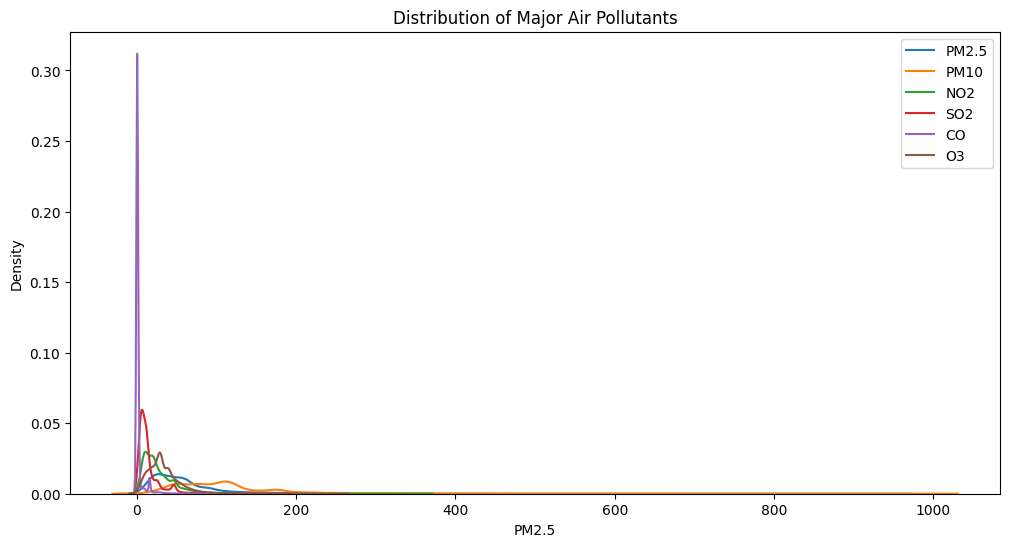

In [103]:
pollutants = ['PM2.5', 'PM10', 'NO2', 'SO2', 'CO', 'O3']

plt.figure(figsize=(12,6))
for p in pollutants:
    sns.kdeplot(df[p], label=p)

plt.legend()
plt.title("Distribution of Major Air Pollutants")
plt.show()

### 3.2 Correlation Between Pollutants

This heatmap shows correlations among pollutants to assess co-movement
and redundancy in pollutant measurements.


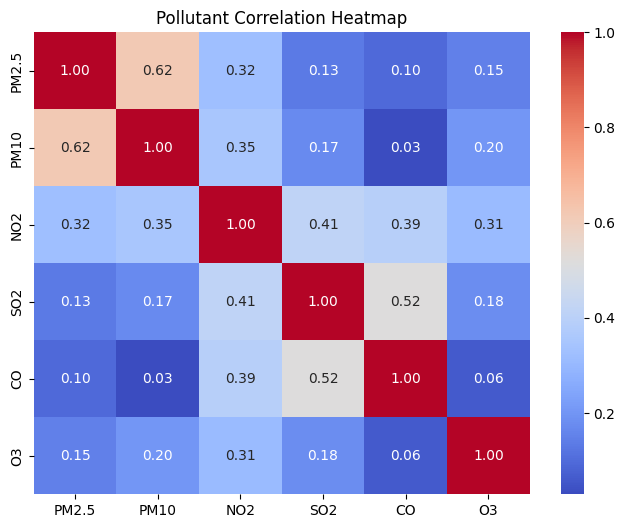

In [104]:
plt.figure(figsize=(8,6))
corr = df[['PM2.5','PM10','NO2','SO2','CO','O3']].corr()

sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Pollutant Correlation Heatmap")
plt.show()


### 3.3 Temporal Behavior of Health Risk Score

This plot shows how pollution exposure evolves over time for a single city,
illustrating persistence and gradual transitions.


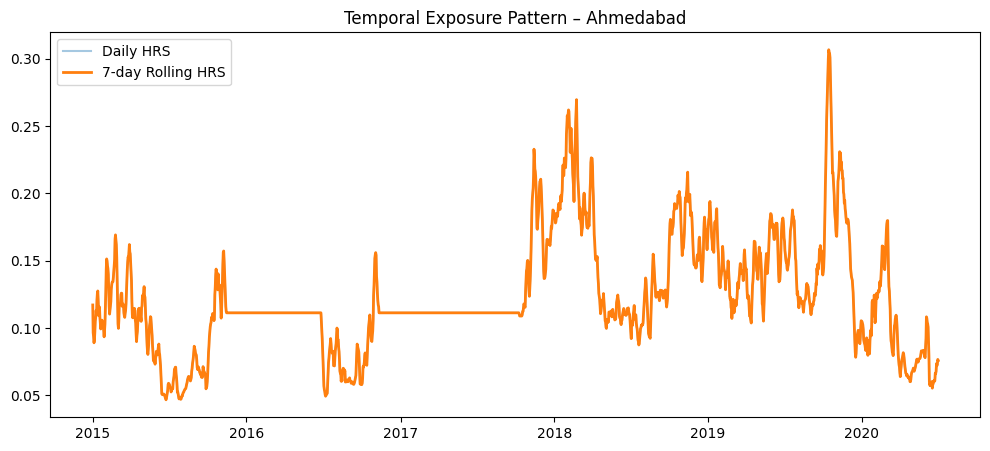

In [105]:
sample_city = df['City'].iloc[0]
city_df = df[df['City'] == sample_city]

plt.figure(figsize=(12,5))
plt.plot(city_df['Date'], city_df['Health_Risk_Score'], alpha=0.4, label='Daily HRS')
plt.plot(city_df['Date'], city_df['HRS_7day'], linewidth=2, label='7-day Rolling HRS')

plt.title(f"Temporal Exposure Pattern – {sample_city}")
plt.legend()
plt.show()


### 3.4 Distribution of Health Risk Labels


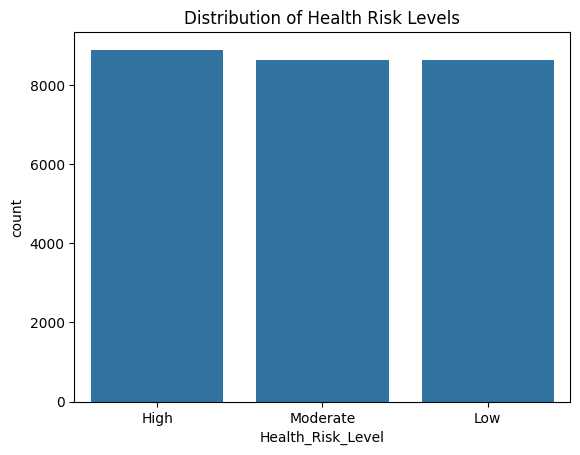

In [111]:
sns.countplot(x=df['Health_Risk_Level'])
plt.title("Distribution of Health Risk Levels")
plt.show()


## 4. Feature Engineering

This section constructs exposure-aware features that capture
pollution accumulation, temporal persistence, and volatility.


In [76]:
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
df[[p + '_norm' for p in pollutants]] = scaler.fit_transform(df[pollutants])

In [77]:
df['Health_Risk_Score'] = (
    0.35 * df['PM2.5_norm'] +
    0.20 * df['PM10_norm'] +
    0.15 * df['NO2_norm'] +
    0.10 * df['SO2_norm'] +
    0.10 * df['CO_norm'] +
    0.10 * df['O3_norm']
)


In [78]:
df = df.sort_values(['City' , 'Date'])

In [79]:
df['HRS_3day'] = (
    df.groupby('City')['Health_Risk_Score']
      .rolling(3, min_periods=1)
      .mean()
      .reset_index(level=0, drop=True)
)

df['HRS_7day'] = (
    df.groupby('City')['Health_Risk_Score']
      .rolling(7, min_periods=1)
      .mean()
      .reset_index(level=0, drop=True)
)


In [80]:
df['HRF_lag1'] = df.groupby('City')['Health_Risk_Score'].shift(1)

In [81]:
df['Health_Risk_Score'] = (
    df.groupby('City')['Health_Risk_Score']
    .rolling(7 , min_periods=2)
    .mean()
    .reset_index(level=0 , drop=True)
)

In [82]:
df['VOC_Index'] = df[['Benzene' , 'Toluene' , 'Xylene']].sum(axis=1 , min_count=1)

## 5. Target Construction

Health risk labels are constructed using prolonged (7-day) exposure
to avoid sensitivity to single-day pollution spikes.


In [112]:
df[['Health_Risk_Score' , 'HRS_3day' , 'HRS_7day']].describe()

,Health_Risk_Score,HRS_3day,HRS_7day
count,26163.000000,26182.000000,26182.000000
mean,0.080539,0.080504,0.080540
std,0.042012,0.043521,0.042024
min,0.011547,0.008952,0.011547
25%,0.051211,0.051211,0.051211
50%,0.069350,0.068649,0.069353
75%,0.101565,0.101263,0.101565
max,0.422256,0.427799,0.422256


In [113]:
label_source = 'HRS_7day'

In [114]:
df = df.dropna(subset=['HRS_7day']).reset_index(drop=True)


In [115]:
low_th , high_th = df['HRS_7day'].quantile([0.33 , 0.66])
low_th , high_th

(0.05569860567023441, 0.08620137278081336)

In [116]:
def risk_label(x):
    if x <= low_th:
        return 'Low'
    elif x <= high_th:
        return 'Moderate'
    else:
        return 'High'

df['Health_Risk_Level'] = df['HRS_7day'].apply(risk_label)


In [117]:
df['Health_Risk_Level'].value_counts(normalize=True)


Health_Risk_Level
High        0.340005
Moderate    0.329998
Low         0.329998
Name: proportion, dtype: float64

In [118]:
df.columns

Index(['City', 'Date', 'PM2.5', 'PM10', 'NO', 'NO2', 'NOx', 'NH3', 'CO', 'SO2',
       'O3', 'Benzene', 'Toluene', 'Xylene', 'year', 'month', 'dayofweek',
       'is_winter', 'PM2.5_norm', 'PM10_norm', 'NO2_norm', 'SO2_norm',
       'CO_norm', 'O3_norm', 'Health_Risk_Score', 'HRS_3day', 'HRS_7day',
       'HRS_lag1', 'VOC_index', 'Health_Risk_Level', 'HRS_7day_std'],
      dtype='object')

In [119]:
df = df.rename(columns={
    'HRF_lag1': 'HRS_lag1',
    'VOC_Index': 'VOC_index'
}
               )

In [120]:
df = df.sort_values(['City', 'Date'])

df['HRS_7day_std'] = (
    df.groupby('City')['Health_Risk_Score']
      .transform(lambda x: x.rolling(window=7, min_periods=3).std())
)


In [121]:
features = [
    'month', 'dayofweek', 'is_winter',
    'HRS_3day', 'HRS_lag1', 'HRS_7day_std',
    'VOC_index'
]

X = df[features]
y = df['Health_Risk_Level']

In [122]:
X = X.fillna(X.median())


## 6. Modeling & Evaluation

Machine learning models are trained using a time-aware split,
with emphasis on detecting high-risk exposure periods.


In [123]:
from sklearn.model_selection import train_test_split
X_train , X_test , y_train , y_test = train_test_split(
    X, y, 
    test_size=0.2 ,
    shuffle=False
)

In [124]:
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression(
    max_iter=1000 
    
)

log_reg.fit(X_train, y_train)
y_pred_lr = log_reg.predict(X_test)

In [125]:
from sklearn.ensemble import  RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=50,
    random_state=42
)

rf.fit(X_train , y_train)
y_pred_rf = rf.predict(X_test)

In [126]:
from sklearn.metrics import classification_report


print("Logistic Regression")
print(classification_report(y_test, y_pred_lr))

print("Random Forest")
print(classification_report(y_test, y_pred_rf))


Logistic Regression
              precision    recall  f1-score   support

        High       0.93      0.90      0.91      1852
         Low       0.81      0.93      0.87      1473
    Moderate       0.84      0.77      0.80      1912

    accuracy                           0.86      5237
   macro avg       0.86      0.87      0.86      5237
weighted avg       0.86      0.86      0.86      5237

Random Forest
              precision    recall  f1-score   support

        High       0.93      0.92      0.92      1852
         Low       0.89      0.89      0.89      1473
    Moderate       0.84      0.85      0.85      1912

    accuracy                           0.89      5237
   macro avg       0.89      0.89      0.89      5237
weighted avg       0.89      0.89      0.89      5237



## 7. Error Analysis & Interpretation

This section examines misclassifications to understand
model behavior near risk boundaries.


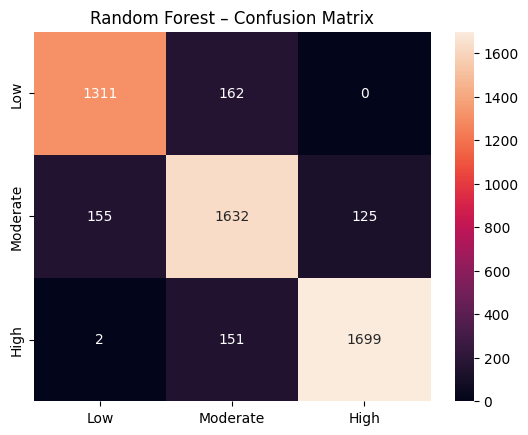

In [127]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test , y_pred_rf,
    labels=['Low' , 'Moderate' , 'High']
)

sns.heatmap(
    cm, annot=True, fmt='d',
    xticklabels=['Low','Moderate','High'],
    yticklabels=['Low','Moderate','High']
)
plt.title("Random Forest – Confusion Matrix")
plt.show()

In [128]:
importance = pd.Series(
    rf.feature_importances_,
    index=features
).sort_values(ascending=False)

importance

HRS_3day        0.457015
HRS_lag1        0.302190
HRS_7day_std    0.108379
VOC_index       0.066371
month           0.029574
dayofweek       0.022830
is_winter       0.013640
dtype: float64

In [129]:
error_df = X_test.copy()
error_df['true'] = y_test.values
error_df['pred'] = y_pred_rf

errors = error_df[error_df['true'] != error_df['pred']]
errors.head()

,month,dayofweek,is_winter,HRS_3day,HRS_lag1,HRS_7day_std,VOC_index,true,pred
20965,10,0,0,0.090063,0.104379,0.001354,3.28,Moderate,High
20976,10,4,0,0.082491,0.066855,0.003491,2.09,High,Moderate
20977,10,5,0,0.073103,0.065686,0.002926,2.95,High,Moderate
20982,11,3,1,0.089812,0.088218,0.002036,2.66,High,Moderate
21097,2,6,1,0.084226,0.083489,0.001569,2.68,High,Moderate


## 8. Conclusions

The model successfully captures exposure-based health risk patterns,
achieving strong recall for high-risk conditions while maintaining
interpretability and conservative error behavior.
